# UTS Machine Learning — Task 3: Customer Clustering

**Objective:** segment 120,000 customers using 90-day behavioral summaries and provide interpretable segment profiles and marketing actions.

**Data:** `clustering.csv.gz` and `kamus_data.md` from the supplied dataset archive.

**Reproducibility:** run this notebook from top to bottom in Google Colab. The setup cells mount Google Drive and extract `data_uts_ml.zip` from `MyDrive/UTS_ML/`.

**Important evaluation note:** HDBSCAN was selected after comparison with MiniBatch K-Means and Gaussian Mixture Models. It produced two clusters and 36 noise observations on the full dataset. The two groups primarily distinguish active from inactive customers; this is a useful lifecycle segmentation, not a set of many fine-grained personas. Full-data HDBSCAN fitting took approximately 30.5 minutes in the recorded Colab run.


In [1]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# 1. ENVIRONMENT AND REPRODUCIBILITY

import os
import zipfile
import random
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

# Display settings
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)

warnings.filterwarnings("default")

# Plot settings
sns.set_theme(style="whitegrid")

print("Environment successfully initialized.")
print("Random seed:", SEED)

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Environment successfully initialized.
Random seed: 42
Pandas version: 2.2.3
NumPy version: 2.4.6


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [3]:
# 2. DATASET EXTRACTION

ZIP_PATH = "/content/drive/MyDrive/UTS_ML/data_uts_ml.zip"
DATA_DIR = "/content/uts_ml_data"

assert os.path.exists(ZIP_PATH), "ZIP file not found!"

os.makedirs(DATA_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:

    zip_ref.extractall(DATA_DIR)

print("Extraction completed.")

print("\nFiles available:")

for filename in sorted(os.listdir(DATA_DIR)):
    filepath = os.path.join(DATA_DIR, filename)

    if os.path.isfile(filepath):
        print(
            filename,
            "|",
            round(os.path.getsize(filepath) / (1024**2), 2),
            "MB"
        )

Extraction completed.

Files available:
clustering.csv.gz | 14.96 MB
kamus_data.md | 0.0 MB
klasifikasi_test.csv.gz | 17.39 MB
klasifikasi_train.csv.gz | 65.42 MB
regresi_test.csv.gz | 8.3 MB
regresi_train.csv.gz | 35.35 MB


In [4]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
DATA_DIR = "/content/uts_ml_data"

CLUSTER_PATH = os.path.join(DATA_DIR, "clustering.csv.gz")
DICTIONARY_PATH = os.path.join(DATA_DIR, "kamus_data.md")

# Verify files
assert os.path.exists(CLUSTER_PATH), "Clustering dataset not found!"
assert os.path.exists(DICTIONARY_PATH), "Data dictionary not found!"

# Load dataset
cluster_df = pd.read_csv(CLUSTER_PATH)

print("Dataset loaded successfully!")
print("Shape:", cluster_df.shape)
display(cluster_df.head())

# Read dictionary
with open(DICTIONARY_PATH, "r", encoding="utf-8") as f:
    dictionary_text = f.read()

print("\nDATA DICTIONARY")
print("=" * 70)
print(dictionary_text)

Dataset loaded successfully!
Shape: (120000, 60)


,id_pelanggan,recency_hari,frekuensi_90h,belanja_90h,rata2_keranjang,item_per_pesanan,porsi_fashion,porsi_elektronik,porsi_kecantikan,porsi_rumah_tangga,porsi_makanan_minuman,porsi_ibu_bayi,porsi_olahraga,porsi_hobi,porsi_otomotif,porsi_kesehatan,porsi_buku_alat_tulis,porsi_voucher_digital,porsi_gadget_aksesoris,porsi_perabot,porsi_pertanian,porsi_lainnya,porsi_jam_pagi,porsi_jam_siang,porsi_jam_sore,porsi_jam_malam,persen_voucher,persen_flash_sale,persen_paylater,persen_cod,retur_90h,rating_beri_rata2,ulasan_90h,sesi_per_minggu,durasi_sesi_menit,rasio_konversi,lama_member_bulan,umur,kota_tier,perangkat,jumlah_alamat,wishlist,klik_iklan_30h,belanja_30h,frekuensi_30h,n01,n02,n03,n04,n05,n06,n07,n08,n09,n10,n11,n12,n13,n14,n15
0,C864291,8.8,6,540100.0,90000.0,3,0.0052,0.0332,0.0885,0.2438,0.1609,0.1198,0.0133,0.0008,0.0666,0.0600,0.0124,0.0355,0.0025,0.0507,0.0369,0.0701,0.0788,0.3856,0.2537,0.2818,0.468,0.019,0.110,0.410,1,4.12,0,9.07,7.46,0.051,16.5,33,2,ios,1,0,2,226600.0,2,80.841,6.424,4.0,0.387,6.820,0.071,-1.872,36.108,3.407,4.0,-0.413,3.468,0.943,0.377,23.328
1,C115620,14.6,6,6035900.0,1006000.0,3,0.1721,0.1303,0.1001,0.1456,0.0474,0.0011,0.0443,0.1306,0.0000,0.0495,0.0107,0.0945,0.0098,0.0389,0.0251,0.0000,0.2587,0.1288,0.3974,0.2152,0.029,0.184,0.013,0.055,0,4.34,2,4.22,10.12,0.109,26.9,42,1,ios,1,5,7,897500.0,2,20.868,10.944,6.0,0.501,19.158,0.006,0.230,41.069,6.218,5.0,-15.530,4.849,0.998,-2.110,67.995
2,C903774,4.1,15,4006600.0,267100.0,1,0.0636,0.0000,0.0164,0.2187,0.1466,0.2112,0.0433,0.0828,0.0258,0.0690,0.0169,0.0003,0.0264,0.0370,0.0151,0.0269,0.3492,0.3385,0.2212,0.0910,0.266,0.055,0.208,0.187,1,4.50,3,3.25,9.00,0.355,10.8,39,1,ios,1,5,5,812500.0,6,73.885,4.804,6.0,-0.669,3.408,0.888,-0.848,80.620,3.552,6.0,2.881,4.269,0.002,-0.812,82.082
3,C716498,21.9,2,659500.0,329800.0,1,0.1899,0.1197,0.0040,0.0536,0.0261,0.0239,0.0195,0.1593,0.0107,0.0493,0.0001,0.0070,0.2974,0.0102,0.0072,0.0221,0.2225,0.3555,0.1737,0.2483,0.681,0.682,0.099,0.444,3,4.51,1,7.31,10.48,0.021,1.5,30,1,android,2,6,2,193700.0,2,79.551,19.952,2.0,1.274,3.231,0.608,1.076,86.465,2.978,3.0,2.790,10.409,0.183,0.285,82.994
4,C936513,7.0,8,4056500.0,507100.0,4,0.0045,0.0503,0.0325,0.0326,0.5501,0.0603,0.0172,0.0024,0.0010,0.0015,0.0393,0.1869,0.0154,0.0011,0.0048,0.0000,0.1539,0.3564,0.3492,0.1405,0.686,0.073,0.119,0.230,0,4.35,3,8.17,9.20,0.075,29.5,37,3,ios,1,11,8,1876300.0,4,23.142,89.557,3.0,1.054,8.881,0.829,-0.621,47.096,6.021,3.0,-24.985,7.796,0.812,1.262,60.364



DATA DICTIONARY
# Kamus data UTS Machine Learning

Data latih regresi dan klasifikasi ditarik pada **31 Agustus 2025**. Data uji mencakup
1 September sampai 31 Oktober 2025. Semua kelompok menerima data yang sama.

## Tugas 1: regresi_train.csv.gz dan regresi_test.csv.gz

Satu baris per paket. Prediksi dibuat saat paket diambil kurir.

| Kolom | Keterangan |
| --- | --- |
| id_paket | ID paket |
| tgl_pickup, jam_pickup | Tanggal dan jam paket diambil kurir |
| layanan | Jenis layanan pengiriman |
| mitra_kurir | Mitra kurir yang mengantar |
| hub_asal, kota_asal | Hub penyortiran dan kota asal |
| pulau_tujuan, kota_tujuan | Pulau dan kota tujuan |
| jarak_km | Jarak rute menurut sistem (km) |
| berat_kg | Berat yang dideklarasikan penjual (kg) |
| volume_liter, jumlah_item, nilai_barang | Volume, jumlah barang, dan nilai barang (rupiah) |
| asuransi, cod | 1 jika diasuransikan, 1 jika bayar di tempat |
| alamat_skor | Skor kelengkapan alamat penerima (0-1) |
| pengalaman_kurir_bulan

In [5]:
# Basic dataset audit
print("DATASET SHAPE:", cluster_df.shape)
print("Duplicate rows:", cluster_df.duplicated().sum())
print("Duplicate customer IDs:", cluster_df["id_pelanggan"].duplicated().sum())
print("Missing customer IDs:", cluster_df["id_pelanggan"].isna().sum())

print("\nDATA TYPES")
display(
    cluster_df.dtypes.value_counts().rename("column_count").to_frame()
)

print("\nMISSING VALUES")
missing_summary = pd.DataFrame({
    "missing_count": cluster_df.isna().sum(),
    "missing_pct": cluster_df.isna().mean() * 100
}).sort_values("missing_count", ascending=False)

display(missing_summary[missing_summary["missing_count"] > 0])

print("\nNUMERICAL SUMMARY")
display(cluster_df.describe().T.round(3))

print("\nCATEGORICAL SUMMARY")
display(cluster_df.select_dtypes(include=["object"]).describe().T)

DATASET SHAPE: (120000, 60)
Duplicate rows: 0
Duplicate customer IDs: 0
Missing customer IDs: 0

DATA TYPES


,column_count
float64,48
int64,10
object,2



MISSING VALUES


,missing_count,missing_pct
rata2_keranjang,6736,5.613333



NUMERICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
recency_hari,120000.0,24.543,49.010,0.200,5.400,10.100,21.800,2.039800e+03
frekuensi_90h,120000.0,9.705,10.922,0.000,3.000,7.000,13.000,2.040000e+02
belanja_90h,120000.0,2936216.427,5716273.207,0.000,410300.000,1136500.000,3060225.000,2.618368e+08
rata2_keranjang,113264.0,280384.330,300796.619,9800.000,108800.000,183900.000,330500.000,6.457500e+06
item_per_pesanan,120000.0,3.042,2.577,1.000,1.000,2.000,4.000,5.100000e+01
porsi_fashion,120000.0,0.141,0.136,0.000,0.040,0.100,0.200,9.700000e-01
porsi_elektronik,120000.0,0.064,0.082,0.000,0.009,0.035,0.087,9.130000e-01
porsi_kecantikan,120000.0,0.091,0.099,0.000,0.020,0.059,0.126,9.370000e-01
porsi_rumah_tangga,120000.0,0.091,0.098,0.000,0.021,0.060,0.129,9.040000e-01
porsi_makanan_minuman,120000.0,0.148,0.140,0.000,0.044,0.107,0.210,9.870000e-01



CATEGORICAL SUMMARY


,count,unique,top,freq
id_pelanggan,120000,120000,C864291,1
perangkat,120000,3,android,77760


In [6]:
# Identify category and time composition columns
category_cols = [c for c in cluster_df.columns if c.startswith("porsi_")
                 and c not in [
                     "porsi_jam_pagi",
                     "porsi_jam_siang",
                     "porsi_jam_sore",
                     "porsi_jam_malam"
                 ]]

time_cols = [
    "porsi_jam_pagi",
    "porsi_jam_siang",
    "porsi_jam_sore",
    "porsi_jam_malam"
]

print("Category proportion columns:", len(category_cols))
print(category_cols)

# Calculate row sums
category_sum = cluster_df[category_cols].sum(axis=1)
time_sum = cluster_df[time_cols].sum(axis=1)

print("\nCATEGORY COMPOSITION")
print(category_sum.describe().round(5))
print("Rows not approximately equal to 1:",
      (~np.isclose(category_sum, 1, atol=0.01)).sum())

print("\nTIME COMPOSITION")
print(time_sum.describe().round(5))
print("Rows not approximately equal to 1:",
      (~np.isclose(time_sum, 1, atol=0.01)).sum())

Category proportion columns: 16
['porsi_fashion', 'porsi_elektronik', 'porsi_kecantikan', 'porsi_rumah_tangga', 'porsi_makanan_minuman', 'porsi_ibu_bayi', 'porsi_olahraga', 'porsi_hobi', 'porsi_otomotif', 'porsi_kesehatan', 'porsi_buku_alat_tulis', 'porsi_voucher_digital', 'porsi_gadget_aksesoris', 'porsi_perabot', 'porsi_pertanian', 'porsi_lainnya']

CATEGORY COMPOSITION
count    120000.00000
mean          0.99999
std           0.00011
min           0.99960
25%           0.99990
50%           1.00000
75%           1.00010
max           1.00050
dtype: float64
Rows not approximately equal to 1: 0

TIME COMPOSITION
count    120000.00000
mean          1.00000
std           0.00006
min           0.99990
25%           1.00000
50%           1.00000
75%           1.00000
max           1.00010
dtype: float64
Rows not approximately equal to 1: 0


In [7]:
# Investigate missing average basket values
missing_basket = cluster_df["rata2_keranjang"].isna()

print("Missing average basket:", missing_basket.sum())
print("Missing percentage:", round(missing_basket.mean() * 100, 2), "%")

print("\nPURCHASE FREQUENCY")
display(
    cluster_df.groupby(missing_basket)[
        ["frekuensi_90h", "frekuensi_30h",
         "belanja_90h", "belanja_30h", "item_per_pesanan"]
    ].agg(["mean", "median", "min", "max"]).round(2)
)

print("\nPURCHASE FREQUENCY COUNTS")
display(
    pd.crosstab(
        missing_basket,
        cluster_df["frekuensi_90h"].eq(0),
        margins=True
    )
)

print("\nDEVICE DISTRIBUTION")
display(
    cluster_df["perangkat"].value_counts(dropna=False)
)

print("\nCUSTOMER CITY TIER")
display(
    cluster_df["kota_tier"].value_counts(dropna=False).sort_index()
)

Missing average basket: 6736
Missing percentage: 5.61 %

PURCHASE FREQUENCY


frekuensi_90h                 frekuensi_30h                belanja_90h                     \
                         mean median min  max          mean median min max        mean     median     min   
rata2_keranjang                                                                                             
False                   10.28    7.0   1  204           3.4    2.0   0  80  3110838.14  1261000.0  9800.0   
True                     0.00    0.0   0    0           0.0    0.0   0   0        0.00        0.0     0.0   

                             belanja_30h                                item_per_pesanan                 
                         max        mean    median     min          max             mean median min max  
rata2_keranjang                                                                                          
False            261836800.0  1103722.17  421200.0  2300.0  101158500.0             3.07    2.0   1  51  
True                     0.0        0.00       0.0     0.0          0.0             2.49    2.0   1  19


PURCHASE FREQUENCY COUNTS


frekuensi_90h,False,True,All
rata2_keranjang,,,
False,113264,0,113264
True,0,6736,6736
All,113264,6736,120000



DEVICE DISTRIBUTION


,count
perangkat,
android,77760
ios,31710
web,10530



CUSTOMER CITY TIER


,count
kota_tier,
1,47961
2,41741
3,30298


In [8]:
# Create a working copy
cluster_work = cluster_df.copy()

# Preserve inactivity information
cluster_work["tidak_aktif_90h"] = (
    cluster_work["frekuensi_90h"] == 0
).astype("int8")

# Fill structurally missing average basket
cluster_work["rata2_keranjang"] = (
    cluster_work["rata2_keranjang"].fillna(0)
)

# Verify
print("Missing values after treatment:",
      cluster_work.isna().sum().sum())

print("\nInactive customers:")
print(cluster_work["tidak_aktif_90h"].value_counts())

print("\nAverage basket by inactivity:")
display(
    cluster_work.groupby("tidak_aktif_90h")[
        ["rata2_keranjang", "frekuensi_90h", "belanja_90h"]
    ].mean().round(2)
)

Missing values after treatment: 0

Inactive customers:
tidak_aktif_90h
0    113264
1      6736
Name: count, dtype: int64

Average basket by inactivity:


,rata2_keranjang,frekuensi_90h,belanja_90h
tidak_aktif_90h,,,
0,280384.33,10.28,3110838.14
1,0.00,0.00,0.00


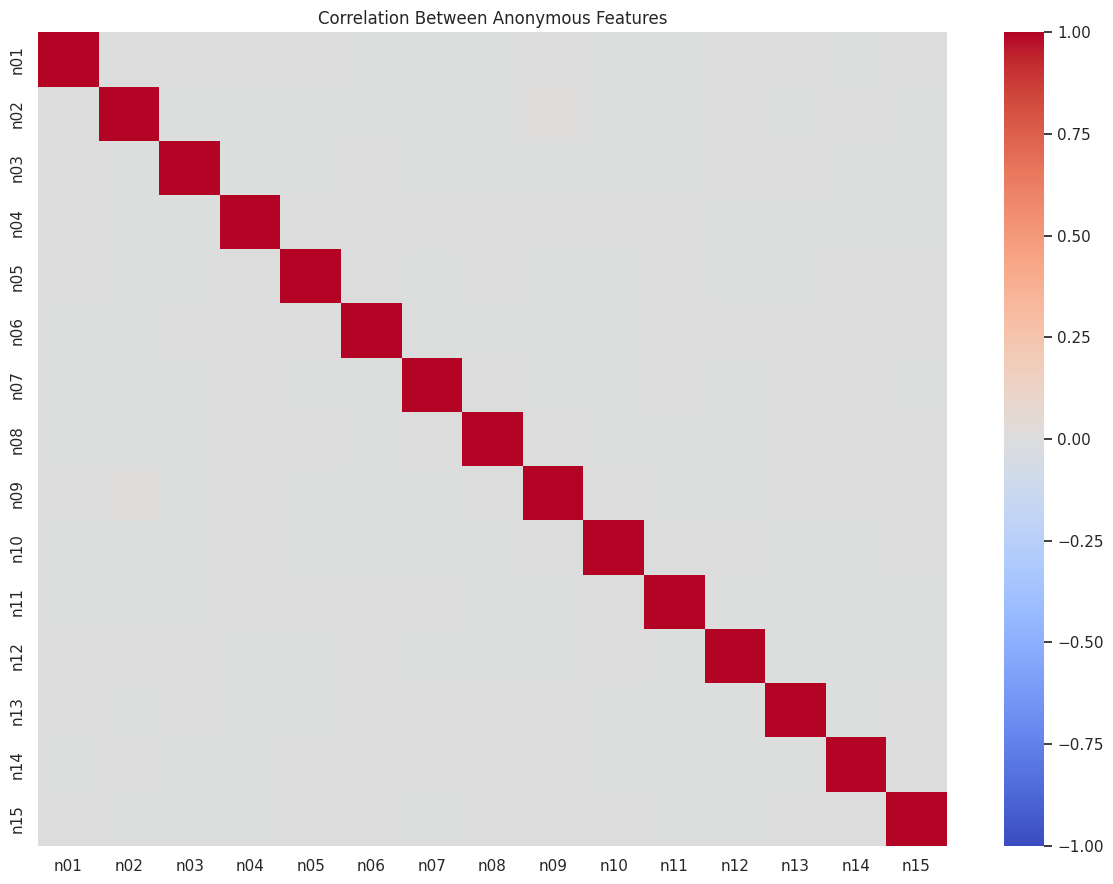

,feature_1,feature_2,correlation,abs_correlation


In [9]:
# Correlation among anonymous features
anonymous_cols = [
    col for col in cluster_work.columns
    if col.startswith("n") and col[1:].isdigit()
]

anonymous_corr = cluster_work[anonymous_cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    anonymous_corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)
plt.title("Correlation Between Anonymous Features")
plt.tight_layout()
plt.show()

# Show strongly correlated pairs
corr_pairs = (
    anonymous_corr.where(
        np.triu(np.ones(anonymous_corr.shape), k=1).astype(bool)
    )
    .stack()
    .reset_index()
)

corr_pairs.columns = ["feature_1", "feature_2", "correlation"]
corr_pairs["abs_correlation"] = corr_pairs["correlation"].abs()

display(
    corr_pairs[corr_pairs["abs_correlation"] >= 0.90]
    .sort_values("abs_correlation", ascending=False)
)

In [10]:
# Select numeric features, excluding customer ID
numeric_cols = cluster_work.select_dtypes(include=np.number).columns.tolist()

# Calculate skewness and key percentiles
skew_report = cluster_work[numeric_cols].agg([
    "min",
    "median",
    "mean",
    "max",
    "skew"
]).T

skew_report = skew_report.sort_values(
    "skew",
    key=lambda x: x.abs(),
    ascending=False
)

display(skew_report.round(3))

,min,median,mean,max,skew
n12,0.000,5.880,19.791,3.932884e+04,149.412
n05,0.000,5.858,19.381,2.562943e+04,115.322
n02,0.017,7.356,19.587,2.533811e+03,13.821
n09,0.015,7.422,19.538,2.843352e+03,12.533
sesi_per_minggu,0.190,5.510,10.072,3.999000e+02,9.194
belanja_30h,0.000,377950.000,1041766.564,1.011585e+08,8.190
recency_hari,0.200,10.100,24.543,2.039800e+03,7.943
belanja_90h,0.000,1136500.000,2936216.427,2.618368e+08,7.468
klik_iklan_30h,0.000,5.000,8.942,2.440000e+02,7.448
wishlist,0.000,10.000,13.435,1.850000e+02,5.763


In [11]:
# Work on a separate transformed dataset
cluster_transformed = cluster_work.copy()

# 1. Log-transform strongly right-skewed, nonnegative features
log_cols = [
    "recency_hari",
    "frekuensi_90h",
    "belanja_90h",
    "rata2_keranjang",
    "item_per_pesanan",
    "frekuensi_30h",
    "belanja_30h",
    "sesi_per_minggu",
    "klik_iklan_30h",
    "wishlist",
    "retur_90h",
    "ulasan_90h",
    "n02",
    "n05",
    "n09",
    "n12"
]

for col in log_cols:
    cluster_transformed[col] = np.log1p(cluster_transformed[col])

# 2. Identify compositional groups
category_cols = [col for col in cluster_work.columns if col.startswith("porsi_")
                 and col not in [
                     "porsi_jam_pagi", "porsi_jam_siang",
                     "porsi_jam_sore", "porsi_jam_malam"
                 ]]

time_cols = [
    "porsi_jam_pagi",
    "porsi_jam_siang",
    "porsi_jam_sore",
    "porsi_jam_malam"
]

# 3. CLR transformation with a small pseudocount for zero proportions
def clr_transform(df, columns, pseudocount=1e-4):
    values = df[columns].to_numpy(dtype=float)
    values = values + pseudocount
    log_values = np.log(values)
    clr_values = log_values - log_values.mean(axis=1, keepdims=True)

    return pd.DataFrame(
        clr_values,
        columns=[col + "_clr" for col in columns],
        index=df.index
    )

category_clr = clr_transform(cluster_work, category_cols)
time_clr = clr_transform(cluster_work, time_cols)

# Replace original proportion columns with CLR features
cluster_transformed = cluster_transformed.drop(
    columns=category_cols + time_cols
)

cluster_transformed = pd.concat(
    [cluster_transformed, category_clr, time_clr],
    axis=1
)

print("Original shape:", cluster_work.shape)
print("Transformed shape:", cluster_transformed.shape)
print("Missing values:", cluster_transformed.isna().sum().sum())
print("Infinite values:", np.isinf(
    cluster_transformed.select_dtypes(include=np.number)
).sum().sum())

display(cluster_transformed.head())

Original shape: (120000, 61)
Transformed shape: (120000, 61)
Missing values: 0
Infinite values: 0


,id_pelanggan,recency_hari,frekuensi_90h,belanja_90h,rata2_keranjang,item_per_pesanan,persen_voucher,persen_flash_sale,persen_paylater,persen_cod,retur_90h,rating_beri_rata2,ulasan_90h,sesi_per_minggu,durasi_sesi_menit,rasio_konversi,lama_member_bulan,umur,kota_tier,perangkat,jumlah_alamat,wishlist,klik_iklan_30h,belanja_30h,frekuensi_30h,n01,n02,n03,n04,n05,n06,n07,n08,n09,n10,n11,n12,n13,n14,n15,tidak_aktif_90h,porsi_fashion_clr,porsi_elektronik_clr,porsi_kecantikan_clr,porsi_rumah_tangga_clr,porsi_makanan_minuman_clr,porsi_ibu_bayi_clr,porsi_olahraga_clr,porsi_hobi_clr,porsi_otomotif_clr,porsi_kesehatan_clr,porsi_buku_alat_tulis_clr,porsi_voucher_digital_clr,porsi_gadget_aksesoris_clr,porsi_perabot_clr,porsi_pertanian_clr,porsi_lainnya_clr,porsi_jam_pagi_clr,porsi_jam_siang_clr,porsi_jam_sore_clr,porsi_jam_malam_clr
0,C864291,2.282382,1.945910,13.199511,11.407576,1.386294,0.468,0.019,0.110,0.410,0.693147,4.12,0.000000,2.309561,7.46,0.051,16.5,33,2,ios,1,0.000000,1.098612,12.330946,1.098612,80.841,2.004718,4.0,0.387,2.056685,0.071,-1.872,36.108,1.483194,4.0,-0.413,1.496941,0.943,0.377,23.328,0,-1.748048,0.089803,1.068377,2.081004,1.665650,1.370903,-0.820500,-3.521115,0.784450,0.680255,-0.890026,0.156591,-2.460243,0.512142,0.195163,0.835594,-1.007154,0.579725,0.161212,0.266217
1,C115620,2.747271,1.945910,15.613236,13.821494,1.386294,0.029,0.184,0.013,0.055,0.000000,4.34,1.098612,1.652497,10.12,0.109,26.9,42,1,ios,1,1.791759,2.079442,13.707370,1.098612,20.868,2.480229,6.0,0.501,3.003601,0.006,0.230,41.069,1.976578,5.0,-15.530,1.766271,0.998,-2.110,67.995,0,2.165648,1.887598,1.624159,1.998541,0.877721,-2.800687,0.810231,1.889896,-5.285594,0.920982,-0.603463,1.566649,-0.690474,0.680553,0.243835,-5.285594,0.112976,-0.584043,0.542115,-0.071048
2,C903774,1.629241,2.772589,15.203454,12.495382,0.693147,0.266,0.055,0.208,0.187,0.693147,4.50,1.386294,1.446919,9.00,0.355,10.8,39,1,ios,1,1.791759,1.791759,13.607872,1.945910,73.885,1.758547,6.0,-0.669,1.483421,0.888,-0.848,80.620,1.515567,6.0,2.881,1.661841,0.002,-0.812,82.082,0,0.973716,-5.483054,-0.377108,2.207690,1.807921,2.172810,0.589991,1.237167,0.073775,1.055086,-0.347255,-4.096759,0.096676,0.433149,-0.459173,0.115368,0.457874,0.426763,0.001462,-0.886099
3,C716498,3.131137,1.098612,13.399239,12.706245,0.693147,0.681,0.682,0.099,0.444,1.386294,4.51,0.693147,2.117460,10.48,0.021,1.5,30,1,android,2,1.945910,1.098612,12.174071,1.098612,79.551,3.042234,2.0,1.274,1.442438,0.608,1.076,86.465,1.380779,3.0,2.790,2.434403,0.183,0.285,82.994,0,2.143044,1.681843,-1.692993,0.879433,0.161779,0.074073,-0.128451,1.967436,-0.724434,0.795970,-4.713418,-1.143886,2.591434,-0.771836,-1.116106,-0.003888,-0.082656,0.385774,-0.330127,0.027008
4,C936513,2.079442,2.197225,15.215831,13.136465,1.609438,0.686,0.073,0.119,0.230,0.000000,4.35,1.386294,2.215937,9.20,0.075,29.5,37,3,ios,1,2.484907,2.197225,14.444813,1.609438,23.142,4.505979,3.0,1.054,2.290614,0.829,-0.621,47.096,1.948906,3.0,-24.985,2.174297,0.812,1.262,60.364,0,-0.866194,1.527741,1.092062,1.095125,3.918032,1.708739,0.458456,-1.475959,-2.296940,-1.922247,1.281516,2.838858,0.348590,-2.209929,-0.803015,-4.694835,-0.391832,0.447550,0.427147,-0.482865


In [12]:
from sklearn.preprocessing import RobustScaler

# Keep customer IDs separately
customer_ids = cluster_transformed["id_pelanggan"].copy()

# Exclude ID and raw categorical column
feature_df = cluster_transformed.drop(
    columns=["id_pelanggan", "perangkat"]
).copy()

# One-hot encode device
device_encoded = pd.get_dummies(
    cluster_transformed["perangkat"],
    prefix="perangkat",
    dtype=float
)

# Robust scaling
scaler = RobustScaler()
X_numeric = pd.DataFrame(
    scaler.fit_transform(feature_df),
    columns=feature_df.columns,
    index=feature_df.index
)

# Balance feature groups by dividing each group by sqrt(number of features)
category_clr_cols = [c for c in X_numeric.columns if c.endswith("_clr")
                     and not c.startswith("porsi_jam_")]
time_clr_cols = [c for c in X_numeric.columns if c.startswith("porsi_jam_")]

# Group weighting
X_numeric[category_clr_cols] /= np.sqrt(len(category_clr_cols))
X_numeric[time_clr_cols] /= np.sqrt(len(time_clr_cols))

# Combine numeric and encoded categorical features
X_cluster = pd.concat(
    [X_numeric, device_encoded],
    axis=1
).astype("float32")

print("Final feature matrix shape:", X_cluster.shape)
print("Missing values:", X_cluster.isna().sum().sum())
print("Infinite values:", np.isinf(X_cluster.to_numpy()).sum())
print("Customer IDs retained separately:", len(customer_ids))

display(X_cluster.head())

Final feature matrix shape: (120000, 62)
Missing values: 0
Infinite values: 0
Customer IDs retained separately: 120000


,recency_hari,frekuensi_90h,belanja_90h,rata2_keranjang,item_per_pesanan,persen_voucher,persen_flash_sale,persen_paylater,persen_cod,retur_90h,rating_beri_rata2,ulasan_90h,sesi_per_minggu,durasi_sesi_menit,rasio_konversi,lama_member_bulan,umur,kota_tier,jumlah_alamat,wishlist,klik_iklan_30h,belanja_30h,frekuensi_30h,n01,n02,n03,n04,n05,n06,n07,n08,n09,n10,n11,n12,n13,n14,n15,tidak_aktif_90h,porsi_fashion_clr,porsi_elektronik_clr,porsi_kecantikan_clr,porsi_rumah_tangga_clr,porsi_makanan_minuman_clr,porsi_ibu_bayi_clr,porsi_olahraga_clr,porsi_hobi_clr,porsi_otomotif_clr,porsi_kesehatan_clr,porsi_buku_alat_tulis_clr,porsi_voucher_digital_clr,porsi_gadget_aksesoris_clr,porsi_perabot_clr,porsi_pertanian_clr,porsi_lainnya_clr,porsi_jam_pagi_clr,porsi_jam_siang_clr,porsi_jam_sore_clr,porsi_jam_malam_clr,perangkat_android,perangkat_ios,perangkat_web
0,-0.098045,-0.106590,-0.370245,-0.553428,0.313964,-0.079051,-0.770419,-0.177083,0.479495,1.0,-0.466667,-0.63093,0.547882,-0.086799,-0.296552,0.030120,0.000000,0.0,0.0,-2.302450,-0.575717,-0.247209,0.000000,0.614733,-0.072235,0.0,0.194695,0.079888,-0.608204,-1.389177,-0.274716,-0.391964,0.0,-0.208354,-0.261369,0.629787,0.274481,-0.528969,0.0,-0.480379,-0.060678,-0.007359,0.124725,-0.006471,0.092746,-0.064336,-0.316826,0.107202,0.073258,-0.025033,-0.066756,-0.367966,0.047250,0.093237,0.041148,-0.483181,0.267241,0.096211,0.041239,0.0,1.0,0.0
1,0.267876,-0.106590,0.830999,1.490913,0.313964,-0.946640,-0.406181,-0.513889,-0.640379,0.0,-0.100000,0.36907,-0.277372,0.394213,0.103448,0.656627,0.692308,-0.5,0.0,-0.582009,0.238944,0.417923,0.000000,-0.585123,0.218210,1.0,0.251752,0.655846,-0.700141,0.169014,-0.175411,-0.093365,0.5,-7.816306,-0.098297,0.707801,-1.570475,0.366044,0.0,0.074558,0.143738,0.065556,0.113667,-0.120594,-0.354313,0.086205,0.186212,-0.369315,0.095504,-0.002520,0.098097,-0.160012,0.063190,0.096393,-0.650959,0.014981,-0.277226,0.274702,-0.104486,0.0,1.0,0.0
2,-0.612143,0.553295,0.627062,0.367833,-0.442507,-0.478261,-0.690949,0.163194,-0.223975,1.0,0.166667,0.63093,-0.535573,0.191682,1.800000,-0.313253,0.461538,-0.5,0.0,-0.582009,0.000000,0.369843,0.924704,0.475567,-0.222597,1.0,-0.333834,-0.268797,0.547383,-0.630096,0.616290,-0.372372,1.0,1.449421,-0.161527,-0.704965,-0.607567,0.648312,0.0,-0.094450,-0.694333,-0.196995,0.141712,0.014136,0.178684,0.065873,0.125531,0.051412,0.107896,0.017608,-0.564025,-0.067519,0.039774,0.050801,-0.040286,0.168370,0.195678,0.021352,-0.456651,0.0,1.0,0.0
3,0.570022,-0.782933,-0.270846,0.546412,-0.442507,0.341897,0.693157,-0.215278,0.586751,2.0,0.183333,0.00000,0.306608,0.459313,-0.503448,-0.873494,-0.230769,-0.5,1.0,-0.433994,-0.575717,-0.323016,0.000000,0.588924,0.561485,-1.0,0.638639,-0.293724,0.151344,0.796145,0.733291,-0.453946,-0.5,1.403624,0.306239,-0.448227,0.206231,0.666587,0.0,0.071353,0.120343,-0.369630,-0.036399,-0.224290,-0.046232,-0.000450,0.193421,-0.011250,0.083951,-0.325401,-0.218798,0.225624,-0.074271,0.008198,-0.053770,-0.072023,0.176502,-0.134031,-0.062118,1.0,0.0,0.0
4,-0.257783,0.094019,0.633222,0.910765,0.557493,0.351779,-0.651214,-0.145833,-0.088328,0.0,-0.083333,0.63093,0.430294,0.227848,-0.131034,0.813253,0.307692,0.5,0.0,0.083548,0.336773,0.774279,0.557493,-0.539628,1.455548,-0.5,0.528529,0.222174,0.463932,-0.461824,-0.054767,-0.110112,-0.5,-12.574736,0.148752,0.443972,0.931009,0.213139,0.0,-0.355338,0.102821,-0.004251,-0.007476,0.319763,0.128951,0.053731,-0.126697,-0.134696,-0.167240,0.145565,0.246834,-0.037918,-0.210378,0.028502,-0.584163,-0.209525,0.205403,0.220828,-0.282423,0.0,1.0,0.0


In [13]:
# Find features with the largest absolute scaled values
max_abs = X_cluster.abs().max().sort_values(ascending=False)

print("Largest maximum absolute values:")
display(max_abs.head(15))

# Inspect selected anonymous features before scaling
display(
    cluster_work[["n04", "n11", "n05", "n12"]]
    .describe(percentiles=[0.90, 0.95, 0.99, 0.995, 0.999])
    .T
)

# Check whether n04 and n11 have similar distributions
print("Correlation n04 vs n11:",
      cluster_work["n04"].corr(cluster_work["n11"]))

print("Correlation n05 vs n12:",
      cluster_work["n05"].corr(cluster_work["n12"]))

Largest maximum absolute values:


,0
n11,251.636139
n04,250.251251
rasio_konversi,28.848276
lama_member_bulan,21.722891
durasi_sesi_menit,10.730560
rata2_keranjang,10.214478
belanja_90h,6.939281
belanja_30h,6.205918
n10,6.000000
n03,5.500000


,count,mean,std,min,50%,90%,95%,99%,99.5%,99.9%,max
n04,120000.0,-0.065667,25.828654,-500.0,-0.0020,3.0870,6.43400,31.35811,60.222250,336.616388,500.000
n11,120000.0,-0.068789,24.921088,-500.0,0.0010,2.9981,6.20800,31.26093,59.897075,288.074526,500.000
n05,120000.0,19.380616,135.801538,0.0,5.8575,36.3080,62.84605,204.12212,320.968275,1009.376370,25629.432
n12,120000.0,19.791031,158.244624,0.0,5.8800,36.3151,63.88070,208.30604,332.959275,1003.464763,39328.844


Correlation n04 vs n11: 0.00145077804467781
Correlation n05 vs n12: -0.001105080559123134


In [14]:
from sklearn.preprocessing import RobustScaler

# Rebuild numerical features before scaling
feature_df = cluster_transformed.drop(
    columns=["id_pelanggan", "perangkat"]
).copy()

# Cap each numerical feature at its 0.5th and 99.5th percentiles
lower_bounds = feature_df.quantile(0.005)
upper_bounds = feature_df.quantile(0.995)

feature_capped = feature_df.clip(
    lower=lower_bounds,
    upper=upper_bounds,
    axis=1
)

# Apply robust scaling
scaler = RobustScaler()
X_numeric = pd.DataFrame(
    scaler.fit_transform(feature_capped),
    columns=feature_capped.columns,
    index=feature_capped.index
)

# Balance compositional groups
category_clr_cols = [
    c for c in X_numeric.columns
    if c.endswith("_clr") and not c.startswith("porsi_jam_")
]

time_clr_cols = [
    c for c in X_numeric.columns
    if c.startswith("porsi_jam_")
]

X_numeric[category_clr_cols] /= np.sqrt(len(category_clr_cols))
X_numeric[time_clr_cols] /= np.sqrt(len(time_clr_cols))

# One-hot encode device
device_encoded = pd.get_dummies(
    cluster_transformed["perangkat"],
    prefix="perangkat",
    dtype=float
)

# Final matrix
X_cluster = pd.concat(
    [X_numeric, device_encoded],
    axis=1
).astype("float32")

print("Final shape:", X_cluster.shape)
print("Largest absolute scaled values:")
display(X_cluster.abs().max().sort_values(ascending=False).head(10))

print("Missing:", X_cluster.isna().sum().sum())
print("Infinite:", np.isinf(X_cluster.to_numpy()).sum())

Final shape: (120000, 62)
Largest absolute scaled values:


,0
n04,32.620632
n11,31.175335
rata2_keranjang,10.214478
belanja_90h,6.939281
rasio_konversi,6.448310
belanja_30h,6.205918
lama_member_bulan,5.548193
sesi_per_minggu,4.792686
durasi_sesi_menit,3.755877
jumlah_alamat,3.000000


Missing: 0
Infinite: 0


In [15]:
!pip -q install hdbscan

from sklearn.cluster import MiniBatchKMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import hdbscan
import time

print("HDBSCAN version:", hdbscan.__version__ if hasattr(hdbscan, "__version__") else "installed")
print("Feature matrix:", X_cluster.shape)

HDBSCAN version: installed
Feature matrix: (120000, 62)


In [16]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np
import time

# Reproducible sample
sample_size = 10000
sample_idx = X_cluster.sample(
    n=sample_size,
    random_state=42
).index

X_sample = X_cluster.loc[sample_idx]

results = []

for k in range(2, 9):
    print(f"Testing k={k}...")

    # MiniBatch K-Means
    km = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=2048,
        n_init=5
    )
    km_labels = km.fit_predict(X_sample)

    km_sil = silhouette_score(
        X_sample,
        km_labels,
        sample_size=3000,
        random_state=42
    )

    results.append({
        "method": "MiniBatchKMeans",
        "k": k,
        "silhouette": km_sil,
        "BIC": np.nan
    })

    # Gaussian Mixture with covariance regularization
    gmm = GaussianMixture(
        n_components=k,
        covariance_type="diag",
        reg_covar=0.01,
        random_state=42,
        n_init=3,
        max_iter=200
    )

    try:
        gmm_labels = gmm.fit_predict(X_sample)

        gmm_sil = silhouette_score(
            X_sample,
            gmm_labels,
            sample_size=3000,
            random_state=42
        )

        results.append({
            "method": "GaussianMixture",
            "k": k,
            "silhouette": gmm_sil,
            "BIC": gmm.bic(X_sample)
        })

    except ValueError as e:
        print(f"GMM failed for k={k}: {e}")

comparison_df = pd.DataFrame(results)

display(
    comparison_df.sort_values(
        ["method", "k"]
    ).round(4)
)

Testing k=2...
Testing k=3...
Testing k=4...
Testing k=5...
Testing k=6...
Testing k=7...
Testing k=8...


,method,k,silhouette,BIC
1,GaussianMixture,2,0.4954,845955.8056
3,GaussianMixture,3,0.1267,801186.4881
5,GaussianMixture,4,0.0383,779319.6020
7,GaussianMixture,5,0.0115,759476.8722
9,GaussianMixture,6,0.0116,729383.6967
11,GaussianMixture,7,0.0133,716334.0681
13,GaussianMixture,8,0.0006,721134.6585
0,MiniBatchKMeans,2,0.4954,NaN
2,MiniBatchKMeans,3,0.5092,NaN
4,MiniBatchKMeans,4,0.5177,NaN


In [17]:
# HDBSCAN comparison on the 10,000-customer sample
hdbscan_results = []

for min_cluster_size in [50, 100, 200]:
    print(f"Testing min_cluster_size={min_cluster_size}...")

    hdb = hdbscan.HDBSCAN(
        min_cluster_size=min_cluster_size,
        min_samples=10,
        metric="euclidean",
        cluster_selection_method="eom"
    )

    labels = hdb.fit_predict(X_sample)

    # Exclude noise (-1) when evaluating cluster separation
    valid_mask = labels != -1
    valid_labels = labels[valid_mask]
    n_clusters = len(set(valid_labels))
    noise_rate = np.mean(~valid_mask)

    if n_clusters >= 2 and valid_mask.sum() > 100:
        sil = silhouette_score(
            X_sample.loc[valid_mask],
            valid_labels,
            sample_size=min(3000, valid_mask.sum()),
            random_state=42
        )
    else:
        sil = np.nan

    hdbscan_results.append({
        "min_cluster_size": min_cluster_size,
        "clusters_found": n_clusters,
        "noise_rate": noise_rate,
        "silhouette_without_noise": sil
    })

display(pd.DataFrame(hdbscan_results).round(4))

Testing min_cluster_size=50...
Testing min_cluster_size=100...
Testing min_cluster_size=200...


,min_cluster_size,clusters_found,noise_rate,silhouette_without_noise
0,50,3,0.0206,0.5147
1,100,2,0.0037,0.4764
2,200,2,0.0037,0.4764


In [18]:
from sklearn.metrics import adjusted_rand_score
from sklearn.cluster import MiniBatchKMeans

# Two independent 80% samples
sample_a = X_cluster.sample(frac=0.8, random_state=42)
sample_b = X_cluster.sample(frac=0.8, random_state=123)

# Fit K-Means on each sample
km_a = MiniBatchKMeans(
    n_clusters=4,
    random_state=42,
    batch_size=2048,
    n_init=5
)

km_b = MiniBatchKMeans(
    n_clusters=4,
    random_state=123,
    batch_size=2048,
    n_init=5
)

labels_a = pd.Series(
    km_a.fit_predict(sample_a),
    index=sample_a.index
)

labels_b = pd.Series(
    km_b.fit_predict(sample_b),
    index=sample_b.index
)

# Compare only customers present in both samples
common_ids = labels_a.index.intersection(labels_b.index)

ari_kmeans = adjusted_rand_score(
    labels_a.loc[common_ids],
    labels_b.loc[common_ids]
)

print("Customers in both samples:", len(common_ids))
print("K-Means stability ARI:", round(ari_kmeans, 4))

Customers in both samples: 76832
K-Means stability ARI: 0.1633


In [19]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import adjusted_rand_score

seed_labels = []

for seed in [10, 20, 30, 40, 50]:
    model = MiniBatchKMeans(
        n_clusters=4,
        random_state=seed,
        batch_size=2048,
        n_init=10,
        max_iter=300
    )

    labels = model.fit_predict(X_sample)
    seed_labels.append(labels)

# Compare every pair of seeds
seed_aris = []

for i in range(len(seed_labels)):
    for j in range(i + 1, len(seed_labels)):
        seed_aris.append(
            adjusted_rand_score(seed_labels[i], seed_labels[j])
        )

print("Mean ARI across seeds:", round(np.mean(seed_aris), 4))
print("Minimum ARI:", round(np.min(seed_aris), 4))
print("All pairwise ARIs:", np.round(seed_aris, 4))

Mean ARI across seeds: 0.6391
Minimum ARI: 0.4014
All pairwise ARIs: [0.8425 0.63   0.826  0.4641 0.59   0.6952 0.4014 0.6359 0.7209 0.5851]


In [20]:
# Smaller HDBSCAN stability test
sample_a_small = X_cluster.sample(
    frac=0.20,
    random_state=42
)

sample_b_small = X_cluster.sample(
    frac=0.20,
    random_state=123
)

hdb_a_small = hdbscan.HDBSCAN(
    min_cluster_size=50,
    min_samples=10,
    metric="euclidean",
    cluster_selection_method="eom"
)

hdb_b_small = hdbscan.HDBSCAN(
    min_cluster_size=50,
    min_samples=10,
    metric="euclidean",
    cluster_selection_method="eom"
)

labels_a_small = pd.Series(
    hdb_a_small.fit_predict(sample_a_small),
    index=sample_a_small.index
)

labels_b_small = pd.Series(
    hdb_b_small.fit_predict(sample_b_small),
    index=sample_b_small.index
)

common_small = labels_a_small.index.intersection(
    labels_b_small.index
)

ari_small = adjusted_rand_score(
    labels_a_small.loc[common_small],
    labels_b_small.loc[common_small]
)

print("Shared customers:", len(common_small))
print("HDBSCAN stability ARI:", round(ari_small, 4))
print("Clusters A:", len(set(labels_a_small) - {-1}))
print("Clusters B:", len(set(labels_b_small) - {-1}))
print("Noise A:", round((labels_a_small == -1).mean(), 4))
print("Noise B:", round((labels_b_small == -1).mean(), 4))

Shared customers: 4882
HDBSCAN stability ARI: 0.9999
Clusters A: 2
Clusters B: 2
Noise A: 0.0011
Noise B: 0.001


In [21]:
import time

# Fit HDBSCAN on all 120,000 customers
start_time = time.time()

hdb_final = hdbscan.HDBSCAN(
    min_cluster_size=50,
    min_samples=10,
    metric="euclidean",
    cluster_selection_method="eom",
    core_dist_n_jobs=-1
)

hdb_labels = hdb_final.fit_predict(X_cluster)

elapsed = time.time() - start_time

# Cluster sizes
cluster_sizes = pd.Series(hdb_labels).value_counts().sort_index()

print(f"Execution time: {elapsed / 60:.2f} minutes")

print("\nCluster sizes:")
display(cluster_sizes.rename("customers").to_frame())

print("\nCluster percentages:")
display(
    (cluster_sizes / len(hdb_labels) * 100)
    .round(3)
    .rename("percentage")
    .to_frame()
)

print("\nTotal clusters excluding noise:", len(set(hdb_labels) - {-1}))
print("Noise customers:", int((hdb_labels == -1).sum()))

Execution time: 30.51 minutes

Cluster sizes:


,customers
-1,36
0,113232
1,6732



Cluster percentages:


,percentage
-1,0.03
0,94.36
1,5.61



Total clusters excluding noise: 2
Noise customers: 36


In [22]:
# Attach cluster labels to original customer data
cluster_profile_df = cluster_work.copy()
cluster_profile_df["cluster"] = hdb_labels

# Select interpretable business features
profile_cols = [
    "recency_hari",
    "frekuensi_90h",
    "belanja_90h",
    "rata2_keranjang",
    "item_per_pesanan",
    "retur_90h",
    "rating_beri_rata2",
    "ulasan_90h",
    "sesi_per_minggu",
    "durasi_sesi_menit",
    "rasio_konversi",
    "lama_member_bulan",
    "umur",
    "persen_voucher",
    "persen_flash_sale",
    "persen_paylater",
    "persen_cod",
    "tidak_aktif_90h"
]

# Calculate median values by cluster
cluster_medians = (
    cluster_profile_df
    .groupby("cluster")[profile_cols]
    .median()
    .round(3)
)

display(cluster_medians)

# Inactivity percentage per cluster
print("\nInactivity rate by cluster (%):")

display(
    cluster_profile_df.groupby("cluster")["tidak_aktif_90h"]
    .mean()
    .mul(100)
    .round(2)
    .rename("inactive_percentage")
    .to_frame()
)

,recency_hari,frekuensi_90h,belanja_90h,rata2_keranjang,item_per_pesanan,retur_90h,rating_beri_rata2,ulasan_90h,sesi_per_minggu,durasi_sesi_menit,rasio_konversi,lama_member_bulan,umur,persen_voucher,persen_flash_sale,persen_paylater,persen_cod,tidak_aktif_90h
cluster,,,,,,,,,,,,,,,,,,
-1,8.75,5.0,1044450.0,164500.0,2.0,0.0,4.43,1.0,4.195,6.955,0.096,17.95,33.0,0.409,0.498,0.090,0.270,0.0
0,9.60,7.0,1261000.0,183900.0,2.0,0.0,4.40,1.0,5.660,7.940,0.101,15.80,33.0,0.513,0.371,0.161,0.251,0.0
1,38.45,0.0,0.0,0.0,2.0,0.0,4.40,0.0,2.550,7.920,0.000,20.70,34.0,0.444,0.328,0.170,0.418,1.0



Inactivity rate by cluster (%):


,inactive_percentage
cluster,
-1,11.11
0,0.00
1,100.00


In [23]:
# Category preference profiles
category_cols = [
    col for col in cluster_work.columns
    if col.startswith("porsi_")
    and not col.startswith("porsi_jam_")
]

time_cols = [
    "porsi_jam_pagi",
    "porsi_jam_siang",
    "porsi_jam_sore",
    "porsi_jam_malam"
]

category_profile = (
    cluster_profile_df
    .groupby("cluster")[category_cols]
    .mean()
    .round(3)
)

time_profile = (
    cluster_profile_df
    .groupby("cluster")[time_cols]
    .mean()
    .round(3)
)

print("Category preferences by cluster:")
display(category_profile)

print("\nShopping time preferences by cluster:")
display(time_profile)

Category preferences by cluster:


,porsi_fashion,porsi_elektronik,porsi_kecantikan,porsi_rumah_tangga,porsi_makanan_minuman,porsi_ibu_bayi,porsi_olahraga,porsi_hobi,porsi_otomotif,porsi_kesehatan,porsi_buku_alat_tulis,porsi_voucher_digital,porsi_gadget_aksesoris,porsi_perabot,porsi_pertanian,porsi_lainnya
cluster,,,,,,,,,,,,,,,,
-1,0.133,0.075,0.114,0.079,0.115,0.042,0.025,0.036,0.021,0.039,0.030,0.072,0.067,0.038,0.029,0.085
0,0.142,0.064,0.091,0.091,0.149,0.059,0.035,0.035,0.027,0.035,0.027,0.068,0.064,0.039,0.019,0.052
1,0.125,0.065,0.085,0.091,0.136,0.053,0.042,0.042,0.031,0.043,0.032,0.065,0.065,0.043,0.021,0.061



Shopping time preferences by cluster:


,porsi_jam_pagi,porsi_jam_siang,porsi_jam_sore,porsi_jam_malam
cluster,,,,
-1,0.228,0.285,0.205,0.283
0,0.259,0.235,0.222,0.284
1,0.246,0.246,0.250,0.259


In [24]:
# Compare cluster separation with and without inactivity indicator

from sklearn.metrics import adjusted_rand_score

# Remove inactivity indicator
X_without_inactive = X_cluster.drop(
    columns=["tidak_aktif_90h"]
)

# Fit HDBSCAN without inactivity indicator
hdb_without_inactive = hdbscan.HDBSCAN(
    min_cluster_size=50,
    min_samples=10,
    metric="euclidean",
    cluster_selection_method="eom",
    core_dist_n_jobs=-1
)

labels_without_inactive = hdb_without_inactive.fit_predict(
    X_without_inactive
)

# Compare new labels with original labels
ari_original_vs_new = adjusted_rand_score(
    hdb_labels,
    labels_without_inactive
)

print("Clusters without inactivity feature:",
      len(set(labels_without_inactive) - {-1}))

print("Noise customers:",
      int((labels_without_inactive == -1).sum()))

print("ARI vs original clustering:",
      round(ari_original_vs_new, 4))

print("\nCluster sizes without inactivity feature:")
display(
    pd.Series(labels_without_inactive)
    .value_counts()
    .sort_index()
    .rename("customers")
    .to_frame()
)

Clusters without inactivity feature: 2
Noise customers: 37
ARI vs original clustering: 1.0

Cluster sizes without inactivity feature:


,customers
-1,37
0,113232
1,6731


In [25]:
# Create final clustering prediction file
prediksi_clustering = pd.DataFrame({
    "id_pelanggan": customer_ids,
    "cluster": hdb_labels
})

# Save CSV
prediksi_clustering.to_csv(
    "cluster.csv",
    index=False
)

# Validate
print("Shape:", prediksi_clustering.shape)
print("Missing values:", prediksi_clustering.isna().sum().sum())
print("Duplicate customer IDs:",
      prediksi_clustering["id_pelanggan"].duplicated().sum())

display(prediksi_clustering.head())

# Download
from google.colab import files
files.download("cluster.csv")

Shape: (120000, 2)
Missing values: 0
Duplicate customer IDs: 0


,id_pelanggan,cluster
0,C864291,0
1,C115620,0
2,C903774,0
3,C716498,0
4,C936513,0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>